In [1]:
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
print(scipy.__version__)

1.16.3


**Loading the Dataset**

In [7]:
from scipy.datasets import electrocardiogram

# Load ECG data
ecg = electrocardiogram()

# Display basic information
print("ECG shape:", ecg.shape)
print("Sampling frequency: 360 Hz")
print("Duration:", len(ecg) / 360, "seconds")
print("First 10 samples:", ecg[:10])

SciPy version: 1.16.3
ECG shape: (108000,)
Sampling frequency: 360 Hz
Duration: 300.0 seconds
First 10 samples: [-0.245 -0.215 -0.185 -0.175 -0.17  -0.17  -0.185 -0.17  -0.16  -0.15 ]


**Visualize the full dataset containg 360 Hz**

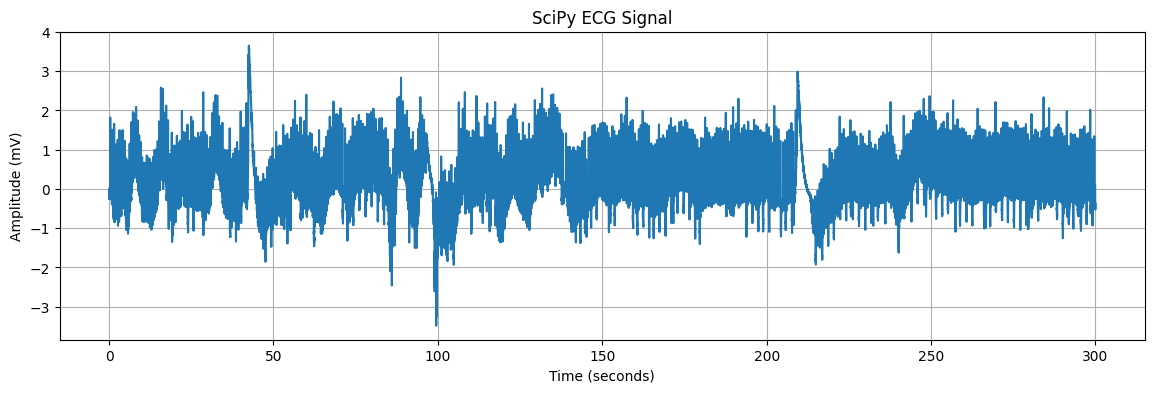

In [8]:
fs = 360  # Sampling frequency in Hz
time = np.arange(len(ecg)) / fs

plt.figure(figsize=(14, 4))
plt.plot(time, ecg)
plt.title("SciPy ECG Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.show()

**Visualize 5 Samples**

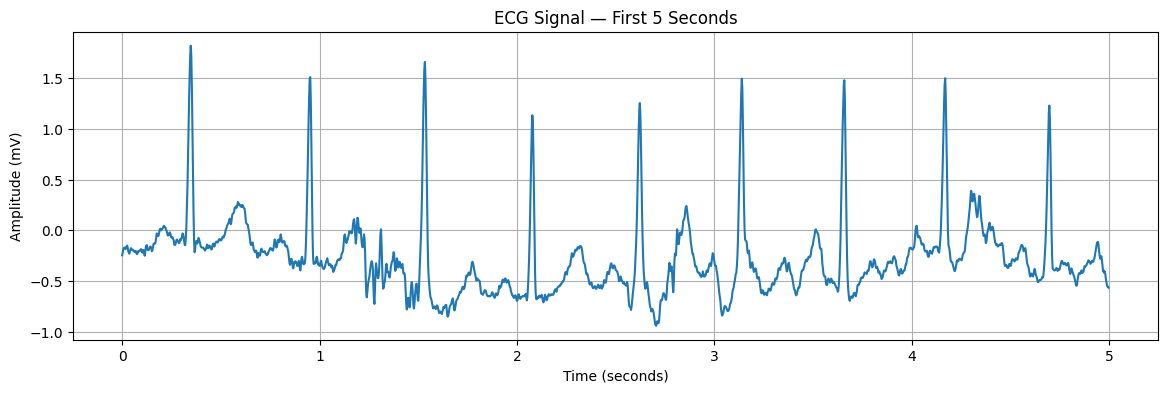

In [9]:
plt.figure(figsize=(14, 4))
plt.plot(time[:5 * fs], ecg[:5 * fs])
plt.title("ECG Signal — First 5 Seconds")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.show()

**R Wave Labeling**

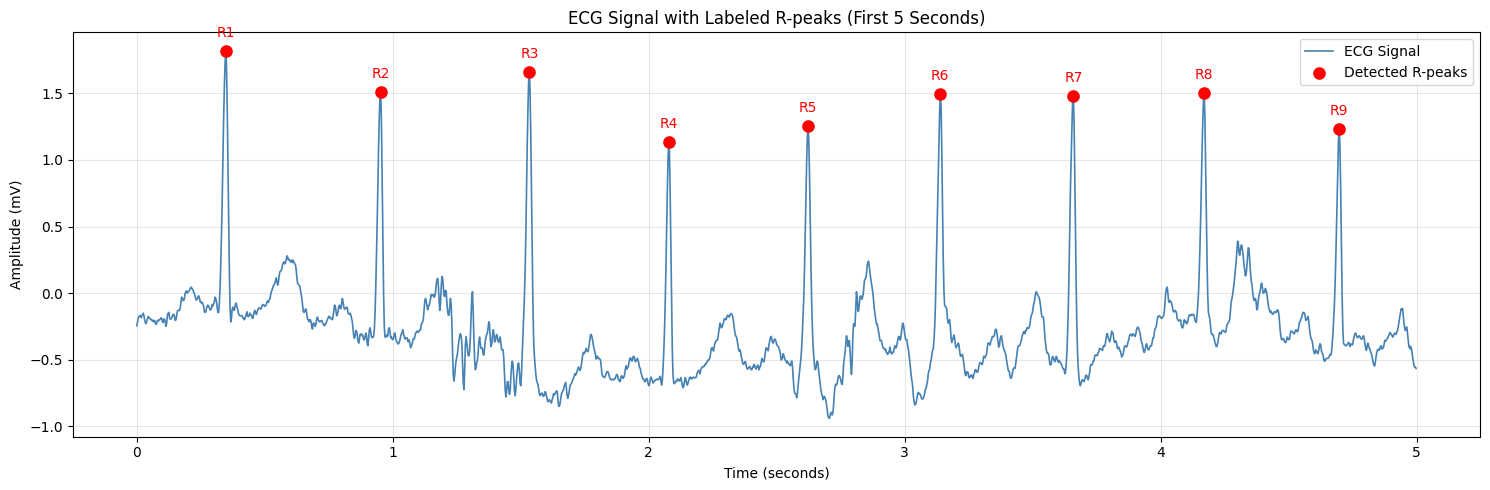

Number of detected R-peaks: 9
R1: Time = 0.347 s, Amplitude = 1.820 mV
R2: Time = 0.953 s, Amplitude = 1.510 mV
R3: Time = 1.533 s, Amplitude = 1.660 mV
R4: Time = 2.078 s, Amplitude = 1.135 mV
R5: Time = 2.622 s, Amplitude = 1.255 mV
R6: Time = 3.139 s, Amplitude = 1.495 mV
R7: Time = 3.658 s, Amplitude = 1.480 mV
R8: Time = 4.169 s, Amplitude = 1.500 mV
R9: Time = 4.697 s, Amplitude = 1.230 mV


In [11]:
from scipy.signal import find_peaks

# 2. Select the first 5 seconds
duration = 5
n_samples = duration * fs

segment = ecg[:n_samples]
time = np.arange(len(segment)) / fs

# 3. Detect candidate R-peaks
peaks, properties = find_peaks(
    segment,
    distance=int(0.25 * fs),
    prominence=0.5
)

# 4. Plot ECG and label R-peaks
plt.figure(figsize=(15, 5))

plt.plot(time, segment, color="steelblue",
         linewidth=1.2, label="ECG Signal")

plt.scatter(
    time[peaks],
    segment[peaks],
    color="red",
    marker="o",
    s=65,
    zorder=3,
    label="Detected R-peaks"
)

# 5. Add labels above each detected peak
for i, peak in enumerate(peaks, start=1):
    plt.annotate(
        f"R{i}",
        (time[peak], segment[peak]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        color="red",
        fontsize=10
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("ECG Signal with Labeled R-peaks (First 5 Seconds)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Print detected peak information
print("Number of detected R-peaks:", len(peaks))

for i, peak in enumerate(peaks, start=1):
    print(
        f"R{i}: Time = {time[peak]:.3f} s, "
        f"Amplitude = {segment[peak]:.3f} mV"
    )